# TPCC Query and Transaction Latency Analysis

This notebook analyzes latency from the uninstrumented TPCC throughput run. It separates transaction-level latency (`raw.csv` and per-procedure result windows) from SQL-shape latency (`dbfs_query_trace.csv` or `postgres_query_trace.csv`).

Configure `throughput_comparison_root` to either an engine result directory containing the BenchBase artifacts directly or a comparison directory containing `dbfs/` and `postgres/`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use('ggplot')
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

throughput_comparison_root = Path(
    '/Users/yohasebe/Documents/dbfs/benchmarking/results/20260904-091550_tcp-nodelay-refactor/tpcc/dbfs'
)

throughput_dbfs_candidate = throughput_comparison_root / 'dbfs'
throughput_dbfs_result_dir = (throughput_dbfs_candidate if any(
    throughput_dbfs_candidate.glob('*.summary.json')) else
                              throughput_comparison_root)

run_configs = {
    'dbfs': {
        'display_name': 'dbfs',
        'result_dir': throughput_dbfs_result_dir,
    },
    'postgres': {
        'display_name': 'PostgreSQL',
        'result_dir': throughput_comparison_root / 'postgres',
    },
}
run_configs = {
    engine: config
    for engine, config in run_configs.items()
    if (config['result_dir'].is_dir()
        and any(config['result_dir'].glob('*.summary.json')))
}
if not run_configs:
    raise FileNotFoundError(
        f'No completed TPCC results found under {throughput_comparison_root}')

missing_engines = sorted({'dbfs', 'postgres'} - set(run_configs))
if missing_engines:
    print('Skipping engines without results: ' + ', '.join(missing_engines))

transaction_names = [
    'NewOrder', 'Payment', 'OrderStatus', 'Delivery', 'StockLevel'
]
query_trace_filenames = {
    'dbfs': 'dbfs_query_trace.csv',
    'postgres': 'postgres_query_trace.csv',
}

Skipping engines without results: postgres


In [2]:
required_suffixes = {
    'summary': '.summary.json',
    'results': '.results.csv',
    'raw': '.raw.csv',
}
procedure_suffix = '.results.'


def find_latest_artifact_prefix(result_dir):
    summaries = sorted(result_dir.glob('*' + required_suffixes['summary']))
    if not summaries:
        raise FileNotFoundError(
            f'No summary artifact found under {result_dir}')
    return summaries[-1].name[:-len(required_suffixes['summary'])]


def load_run(engine, config):
    result_dir = config['result_dir']
    label = find_latest_artifact_prefix(result_dir)
    artifacts = {
        name: result_dir / f'{label}{suffix}'
        for name, suffix in required_suffixes.items()
    }
    with artifacts['summary'].open() as handle:
        summary = json.load(handle)

    procedure_dfs = {
        path.stem.split('.results.', 1)[1]: pd.read_csv(path)
        for path in sorted(result_dir.glob(f'{label}{procedure_suffix}*.csv'))
    }
    trace_path = result_dir / query_trace_filenames[engine]
    query_trace_df = pd.read_csv(trace_path) if trace_path.exists() else None

    return {
        **config,
        'label': label,
        'summary': summary,
        'results_df': pd.read_csv(artifacts['results']),
        'raw_df': pd.read_csv(artifacts['raw']),
        'procedure_dfs': procedure_dfs,
        'query_trace_path': trace_path,
        'query_trace_df': query_trace_df,
    }


runs = {
    engine: load_run(engine, config)
    for engine, config in run_configs.items()
}
validation_df = pd.DataFrame([{
    'Engine':
    run['display_name'],
    'Run Label':
    run['label'],
    'Raw Requests':
    len(run['raw_df']),
    'Procedure Files':
    len(run['procedure_dfs']),
    'Query Trace':
    str(run['query_trace_path']),
    'Query Trace Rows':
    0 if run['query_trace_df'] is None else len(run['query_trace_df']),
} for run in runs.values()])
validation_df

,Engine,Run Label,Raw Requests,Procedure Files,Query Trace,Query Trace Rows
0,dbfs,tpcc_2026-09-04_00-24-58,43243,5,/Users/yohasebe/Documents/dbfs/benchmarking/re...,31


## Overall transaction latency

The table uses the BenchBase summary, while the time-series plot uses five-second result windows.

In [3]:
overall_latency_rows = []
for run in runs.values():
    summary = run['summary']
    latency = summary['Latency Distribution']
    overall_latency_rows.append({
        'Engine':
        run['display_name'],
        'Measured Requests':
        summary['Measured Requests'],
        'Average (ms)':
        latency['Average Latency (microseconds)'] / 1000,
        'Median (ms)':
        latency['Median Latency (microseconds)'] / 1000,
        'P95 (ms)':
        latency['95th Percentile Latency (microseconds)'] / 1000,
        'P99 (ms)':
        latency['99th Percentile Latency (microseconds)'] / 1000,
        'Maximum (ms)':
        latency['Maximum Latency (microseconds)'] / 1000,
    })

overall_latency_df = pd.DataFrame(overall_latency_rows).set_index('Engine')
overall_latency_df

,Measured Requests,Average (ms),Median (ms),P95 (ms),P99 (ms),Maximum (ms)
Engine,,,,,,
dbfs,43243,6.922,5.926,15.301,22.560,461.045


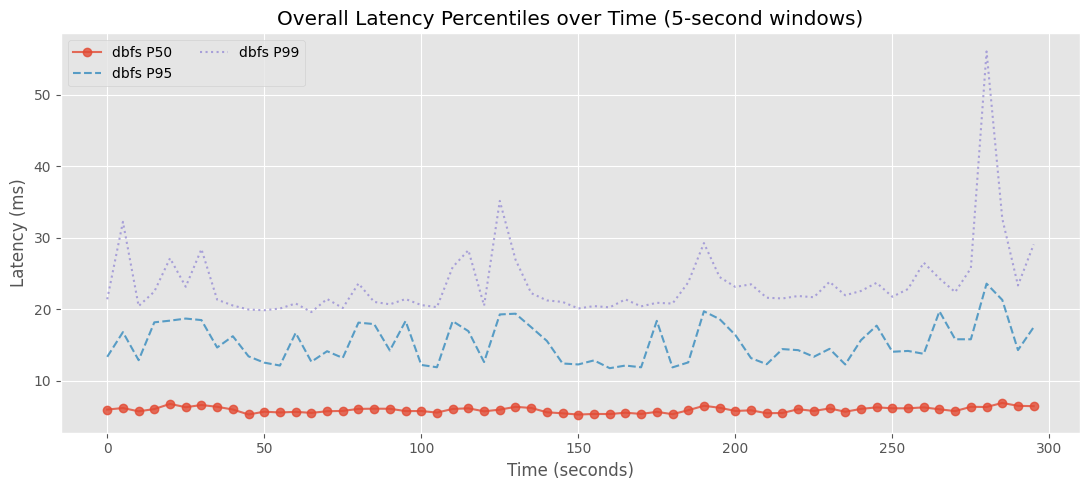

In [4]:
fig, axis = plt.subplots(figsize=(11, 5))
for run in runs.values():
    results_df = run['results_df']
    label = run['display_name']
    axis.plot(results_df['Time (seconds)'],
              results_df['Median Latency (millisecond)'],
              marker='o',
              alpha=0.8,
              label=f'{label} P50')
    axis.plot(results_df['Time (seconds)'],
              results_df['95th Percentile Latency (millisecond)'],
              linestyle='--',
              alpha=0.8,
              label=f'{label} P95')
    axis.plot(results_df['Time (seconds)'],
              results_df['99th Percentile Latency (millisecond)'],
              linestyle=':',
              alpha=0.8,
              label=f'{label} P99')

axis.set_title('Overall Latency Percentiles over Time (5-second windows)')
axis.set_xlabel('Time (seconds)')
axis.set_ylabel('Latency (ms)')
axis.legend(ncol=2)
fig.tight_layout()
plt.show()

## Transaction latency distributions

These histograms use individual requests from `raw.csv`. Every chart uses the same logarithmic latency bins. The y-axis is normalized within each engine or transaction type, so TPCC transaction ratios do not obscure distribution shape.

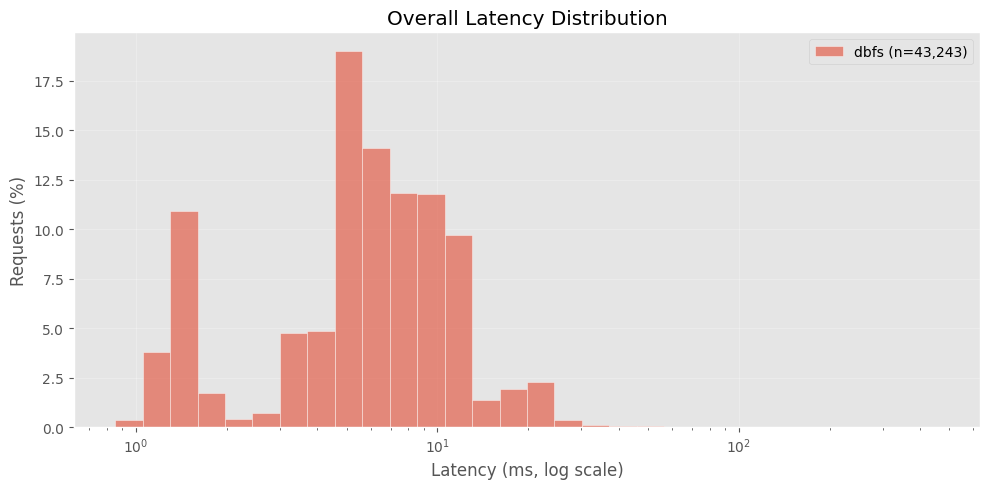

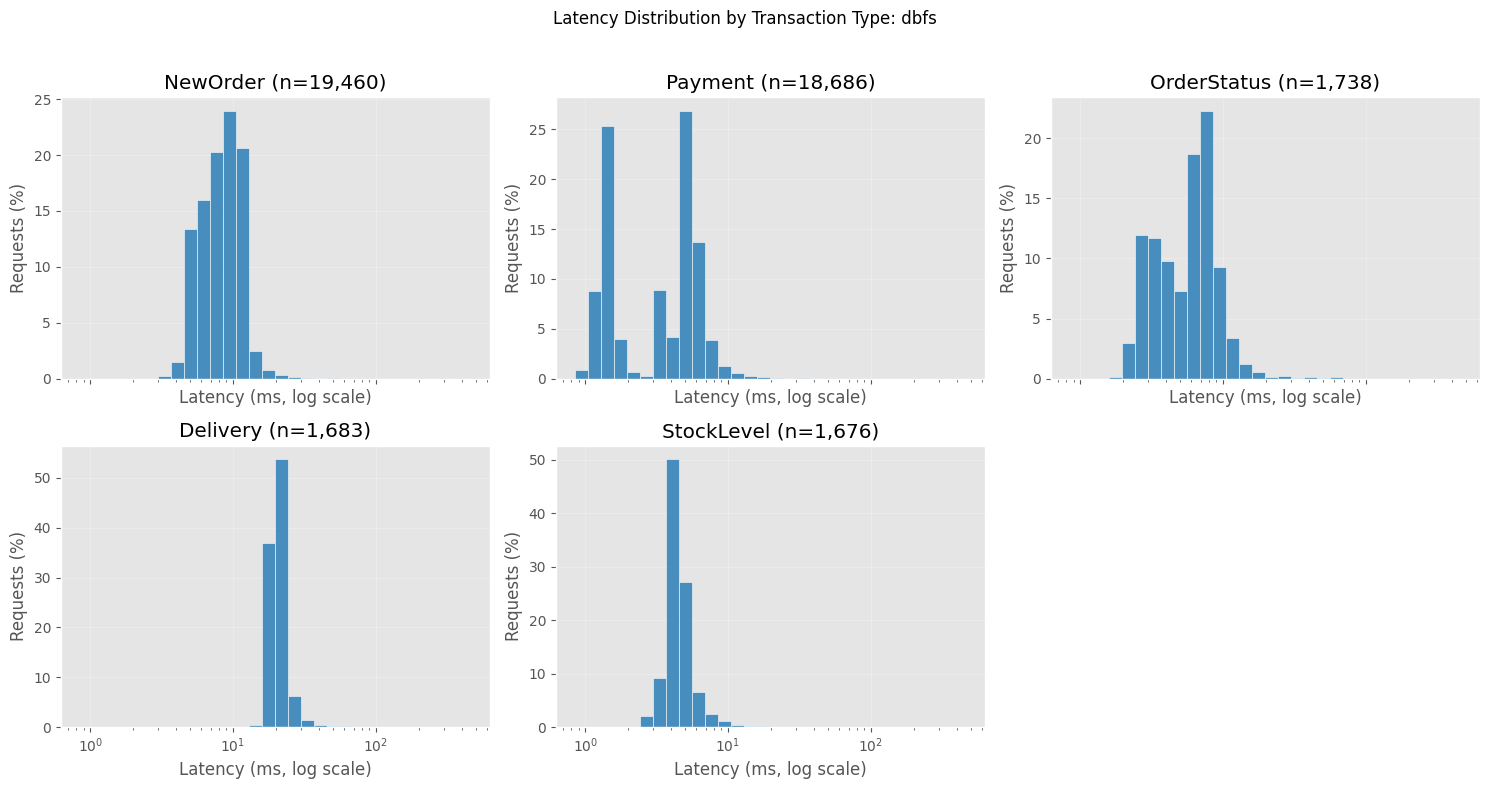

In [5]:
raw_latency_frames = []
for run in runs.values():
    frame = run['raw_df'][['Transaction Name',
                           'Latency (microseconds)']].copy()
    frame['Engine'] = run['display_name']
    frame['Latency (ms)'] = (
        pd.to_numeric(frame['Latency (microseconds)'], errors='coerce') / 1000)
    raw_latency_frames.append(frame.dropna(subset=['Latency (ms)']))

raw_latency_df = pd.concat(raw_latency_frames, ignore_index=True)
raw_latency_df = raw_latency_df[raw_latency_df['Latency (ms)'] > 0]
latency_bin_edges = np.geomspace(raw_latency_df['Latency (ms)'].min(),
                                 raw_latency_df['Latency (ms)'].max(),
                                 num=31)

fig, axis = plt.subplots(figsize=(10, 5))
for display_name, engine_df in raw_latency_df.groupby('Engine', sort=False):
    latency_ms = engine_df['Latency (ms)']
    axis.hist(latency_ms,
              bins=latency_bin_edges,
              weights=np.full(len(latency_ms), 100 / len(latency_ms)),
              alpha=0.6,
              edgecolor='white',
              label=f'{display_name} (n={len(latency_ms):,})')
axis.set_xscale('log')
axis.set_title('Overall Latency Distribution')
axis.set_xlabel('Latency (ms, log scale)')
axis.set_ylabel('Requests (%)')
axis.grid(True, alpha=0.25)
axis.legend()
fig.tight_layout()
plt.show()

for display_name, engine_df in raw_latency_df.groupby('Engine', sort=False):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
    axes = axes.ravel()

    for axis, transaction_name in zip(axes, transaction_names):
        latency_ms = engine_df.loc[engine_df['Transaction Name'] ==
                                   transaction_name, 'Latency (ms)']
        axis.hist(latency_ms,
                  bins=latency_bin_edges,
                  weights=np.full(len(latency_ms), 100 / len(latency_ms)),
                  color='tab:blue',
                  alpha=0.8,
                  edgecolor='white')
        axis.set_xscale('log')
        axis.set_title(f'{transaction_name} (n={len(latency_ms):,})')
        axis.set_xlabel('Latency (ms, log scale)')
        axis.set_ylabel('Requests (%)')
        axis.grid(True, alpha=0.25)

    for axis in axes[len(transaction_names):]:
        axis.set_visible(False)

    fig.suptitle(f'Latency Distribution by Transaction Type: {display_name}')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

In [6]:
variability_rows = []
for (engine, transaction_name), group in raw_latency_df.groupby(
    ['Engine', 'Transaction Name'], sort=False):
    latency_ms = group['Latency (ms)']
    variability_rows.append({
        'Engine': engine,
        'Transaction': transaction_name,
        'Requests': len(latency_ms),
        'Mean (ms)': latency_ms.mean(),
        'Std Dev (ms)': latency_ms.std(),
        'CV': latency_ms.std() / latency_ms.mean(),
        'P25 (ms)': latency_ms.quantile(0.25),
        'Median (ms)': latency_ms.median(),
        'P75 (ms)': latency_ms.quantile(0.75),
        'P95 (ms)': latency_ms.quantile(0.95),
        'P99 (ms)': latency_ms.quantile(0.99),
        'Maximum (ms)': latency_ms.max(),
    })

latency_variability_df = pd.DataFrame(variability_rows).sort_values(
    ['Engine', 'Median (ms)'])
display(latency_variability_df)

,Engine,Transaction,Requests,Mean (ms),Std Dev (ms),CV,P25 (ms),Median (ms),P75 (ms),P95 (ms),P99 (ms),Maximum (ms)
0,dbfs,Payment,18686,3.902,3.017,0.773,1.398,3.809,5.419,7.348,11.427,131.382
2,dbfs,StockLevel,1676,4.717,2.591,0.549,3.969,4.341,4.917,6.848,10.728,86.583
3,dbfs,OrderStatus,1738,6.249,3.925,0.628,3.578,6.223,7.689,11.015,17.390,65.254
1,dbfs,NewOrder,19460,8.811,4.981,0.565,6.466,8.445,10.529,12.656,18.086,200.590
4,dbfs,Delivery,1683,21.506,11.894,0.553,19.310,20.292,21.636,26.833,37.774,461.045


## Raw request latency over time by transaction type

Each point is one request from `raw.csv`. The first chart combines all transaction types, followed by separate charts for each type. The gray bars use the right-hand axis and show request counts in five-second windows. This avoids treating unstable percentiles from one or two low-frequency requests as if they represented the whole window.

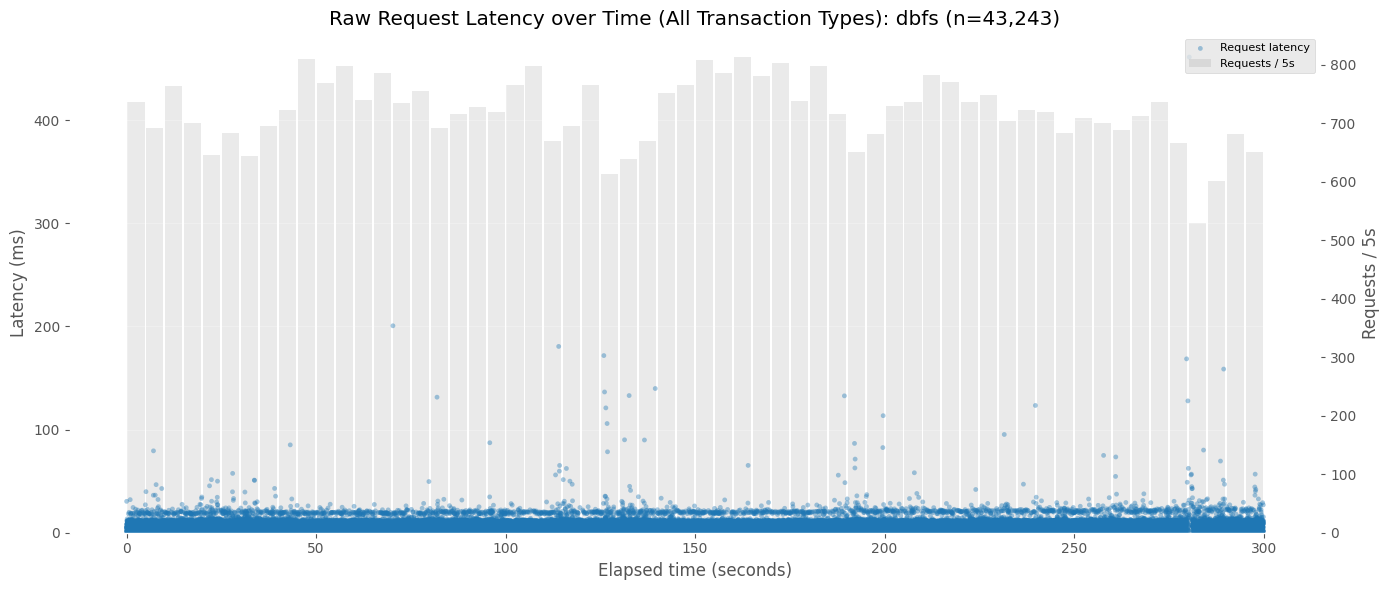

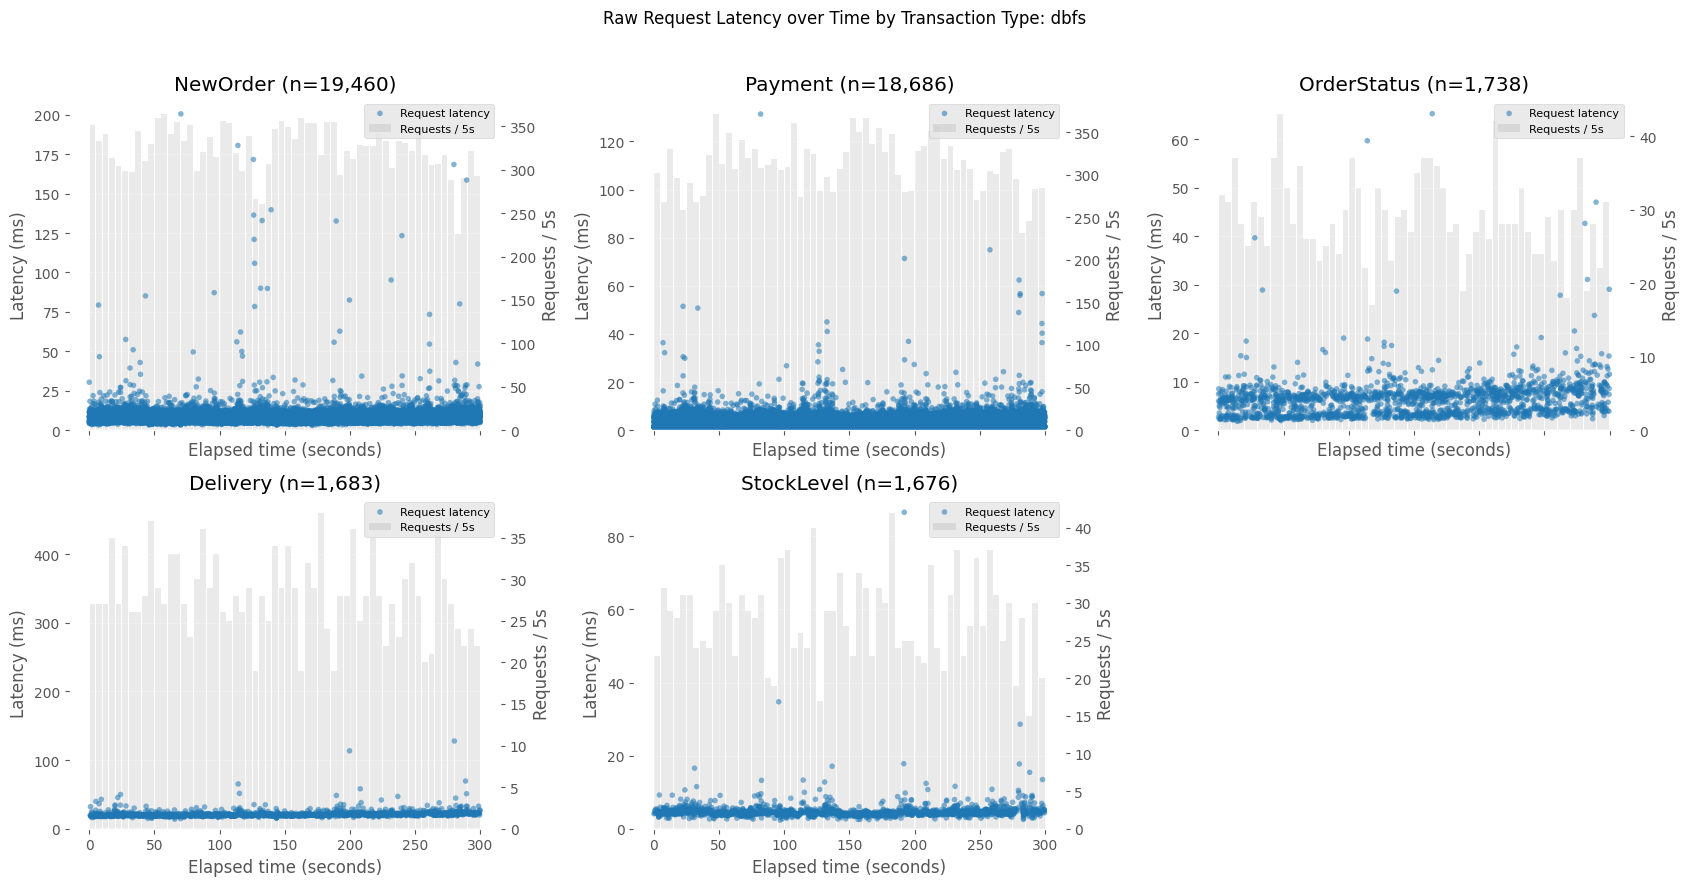

In [7]:
request_count_window_seconds = 5

for run in runs.values():
    request_df = run['raw_df'][[
        'Transaction Name',
        'Start Time (microseconds)',
        'Latency (microseconds)',
    ]].copy()
    request_df['Start Time'] = pd.to_numeric(
        request_df['Start Time (microseconds)'], errors='coerce')
    request_df['Latency (ms)'] = pd.to_numeric(
        request_df['Latency (microseconds)'], errors='coerce') / 1000
    request_df = request_df.dropna(subset=['Start Time', 'Latency (ms)'])
    request_df = request_df[request_df['Latency (ms)'] > 0]

    start_delta = request_df['Start Time'] - request_df['Start Time'].min()
    expected_run_seconds = run['summary'][
        'Elapsed Time (nanoseconds)'] / 1_000_000_000
    start_time_scale = (1_000_000 if start_delta.max() > expected_run_seconds *
                        1000 else 1)
    request_df['Elapsed Time (seconds)'] = start_delta / start_time_scale
    request_df['Window Start (seconds)'] = (
        request_df['Elapsed Time (seconds)'] // request_count_window_seconds *
        request_count_window_seconds)

    overall_request_counts = request_df.groupby(
        'Window Start (seconds)').size()
    fig, axis = plt.subplots(figsize=(14, 6))
    count_axis = axis.twinx()
    count_axis.bar(
        overall_request_counts.index + request_count_window_seconds / 2,
        overall_request_counts.values,
        width=request_count_window_seconds * 0.9,
        color='gray',
        alpha=0.16,
        label=f'Requests / {request_count_window_seconds}s',
    )
    axis.scatter(
        request_df['Elapsed Time (seconds)'],
        request_df['Latency (ms)'],
        s=12,
        alpha=0.4,
        color='tab:blue',
        edgecolors='none',
        label='Request latency',
    )
    axis.set_zorder(count_axis.get_zorder() + 1)
    axis.patch.set_visible(False)
    axis.set_title(f'Raw Request Latency over Time (All Transaction Types): '
                   f"{run['display_name']} (n={len(request_df):,})")
    axis.set_xlabel('Elapsed time (seconds)')
    axis.set_ylabel('Latency (ms)')
    axis.set_ylim(bottom=0)
    count_axis.set_ylabel(f'Requests / {request_count_window_seconds}s')
    count_axis.set_ylim(bottom=0)
    axis.grid(True, alpha=0.25)
    latency_handles, latency_labels = axis.get_legend_handles_labels()
    count_handles, count_labels = count_axis.get_legend_handles_labels()
    axis.legend(latency_handles + count_handles,
                latency_labels + count_labels,
                loc='upper right',
                fontsize=8)
    fig.tight_layout()
    plt.show()

    fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True)
    axes = axes.ravel()

    for axis, transaction_name in zip(axes, transaction_names):
        transaction_df = request_df[request_df['Transaction Name'] ==
                                    transaction_name]
        request_counts = transaction_df.groupby(
            'Window Start (seconds)').size()
        count_axis = axis.twinx()
        count_axis.bar(
            request_counts.index + request_count_window_seconds / 2,
            request_counts.values,
            width=request_count_window_seconds * 0.9,
            color='gray',
            alpha=0.16,
            label=f'Requests / {request_count_window_seconds}s',
        )
        axis.scatter(
            transaction_df['Elapsed Time (seconds)'],
            transaction_df['Latency (ms)'],
            s=16,
            alpha=0.55,
            color='tab:blue',
            edgecolors='none',
            label='Request latency',
        )
        axis.set_zorder(count_axis.get_zorder() + 1)
        axis.patch.set_visible(False)
        axis.set_title(f'{transaction_name} (n={len(transaction_df):,})')
        axis.set_xlabel('Elapsed time (seconds)')
        axis.set_ylabel('Latency (ms)')
        axis.set_ylim(bottom=0)
        count_axis.set_ylabel(f'Requests / {request_count_window_seconds}s')
        count_axis.set_ylim(bottom=0)
        axis.grid(True, alpha=0.25)

        latency_handles, latency_labels = axis.get_legend_handles_labels()
        count_handles, count_labels = count_axis.get_legend_handles_labels()
        axis.legend(latency_handles + count_handles,
                    latency_labels + count_labels,
                    loc='upper right',
                    fontsize=8)

    for axis in axes[len(transaction_names):]:
        axis.set_visible(False)

    fig.suptitle(f'Raw Request Latency over Time by Transaction Type: '
                 f"{run['display_name']}")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

## SQL-shape latency

The query-trace files contain aggregates by normalized SQL shape. They can rank total time, mean latency, and maximum latency, but they do not contain individual executions and therefore cannot produce per-shape latency histograms.

In [8]:
def summarize_dbfs_query_trace(trace_df):
    summary_df = trace_df.copy()
    summary_df['sample_sql'] = summary_df['sample_sql'].fillna(
        summary_df['shape_key'])
    summary_df['total_elapsed_ms'] = summary_df['total_elapsed_us'] / 1000.0
    summary_df['mean_elapsed_ms'] = summary_df['mean_elapsed_us'] / 1000.0
    summary_df['p95_elapsed_ms'] = pd.NA
    summary_df['max_elapsed_ms'] = summary_df['max_elapsed_us'] / 1000.0
    summary_df = summary_df.sort_values(['total_elapsed_ms', 'executions'],
                                        ascending=[False, False])
    return summary_df[[
        'kind',
        'shape_key',
        'sample_sql',
        'executions',
        'total_elapsed_ms',
        'mean_elapsed_ms',
        'p95_elapsed_ms',
        'max_elapsed_ms',
        'failures',
    ]]


def summarize_postgres_server_query_trace(trace_df):
    summary_df = trace_df.copy()
    summary_df['kind'] = 'QUERY'
    summary_df['shape_key'] = summary_df['query'].str.replace(
        r'\s+', ' ', regex=True).str.strip()
    summary_df['sample_sql'] = summary_df['query']
    summary_df['executions'] = summary_df['calls']
    summary_df['total_elapsed_ms'] = summary_df['total_exec_time']
    summary_df['mean_elapsed_ms'] = summary_df['mean_exec_time']
    summary_df['p95_elapsed_ms'] = pd.NA
    summary_df['max_elapsed_ms'] = summary_df['max_exec_time']
    summary_df['failures'] = 0
    summary_df = summary_df.sort_values(['total_elapsed_ms', 'executions'],
                                        ascending=[False, False])
    return summary_df[[
        'kind',
        'shape_key',
        'sample_sql',
        'executions',
        'total_elapsed_ms',
        'mean_elapsed_ms',
        'p95_elapsed_ms',
        'max_elapsed_ms',
        'failures',
    ]]


def summarize_postgres_query_trace(trace_df):
    if {
            'query', 'calls', 'total_exec_time', 'mean_exec_time',
            'max_exec_time'
    }.issubset(trace_df.columns):
        return summarize_postgres_server_query_trace(trace_df)
    return summarize_dbfs_query_trace(trace_df)


def escape_plot_label(text):
    return text.replace('$', r'\$')


def build_shared_trace_comparison(trace_summaries):
    if not {'dbfs', 'postgres'}.issubset(trace_summaries):
        return None

    shared_df = trace_summaries['dbfs'].merge(
        trace_summaries['postgres'],
        on='shape_key',
        how='inner',
        suffixes=('_dbfs', '_postgres'),
    )
    if shared_df.empty:
        return shared_df

    shared_df['sample_sql'] = shared_df['sample_sql_dbfs'].fillna(
        shared_df['sample_sql_postgres'])
    shared_df['combined_total_elapsed_ms'] = (
        shared_df['total_elapsed_ms_dbfs'] +
        shared_df['total_elapsed_ms_postgres'])
    shared_df['combined_max_elapsed_ms'] = shared_df[[
        'max_elapsed_ms_dbfs',
        'max_elapsed_ms_postgres',
    ]].max(axis=1)
    shared_df['label'] = shared_df['sample_sql'].str.slice(0, 96)
    shared_df['plot_label'] = shared_df['label'].map(escape_plot_label)
    return shared_df.sort_values(
        ['combined_total_elapsed_ms', 'combined_max_elapsed_ms'],
        ascending=[False, False],
    )


trace_summaries = {}
for engine, run in runs.items():
    trace_df = run['query_trace_df']
    if trace_df is None or trace_df.empty:
        print(
            f"{run['display_name']}: {query_trace_filenames[engine]} was not found."
        )
        continue

    if engine == 'dbfs':
        engine_summary_df = summarize_dbfs_query_trace(trace_df.copy())
    else:
        engine_summary_df = summarize_postgres_query_trace(trace_df.copy())

    engine_summary_df['Engine'] = run['display_name']
    engine_summary_df['time_share_pct'] = (
        engine_summary_df['total_elapsed_ms'] /
        engine_summary_df['total_elapsed_ms'].sum() * 100)
    engine_summary_df['label'] = engine_summary_df['sample_sql'].str.slice(
        0, 96)
    engine_summary_df['plot_label'] = engine_summary_df['label'].map(
        escape_plot_label)
    trace_summaries[engine] = engine_summary_df

for engine, summary_df in trace_summaries.items():
    display_name = runs[engine]['display_name']
    print(f'Top query shapes for {display_name}')
    display(summary_df[[
        'kind',
        'executions',
        'time_share_pct',
        'total_elapsed_ms',
        'mean_elapsed_ms',
        'p95_elapsed_ms',
        'max_elapsed_ms',
        'failures',
        'sample_sql',
    ]].head(15))

shared_trace_df = build_shared_trace_comparison(trace_summaries)
if shared_trace_df is not None:
    overlap_summary_df = pd.DataFrame([{
        'dbfs_shapes':
        len(trace_summaries['dbfs']),
        'postgres_shapes':
        len(trace_summaries['postgres']),
        'shared_shapes':
        len(shared_trace_df),
        'dbfs_only':
        len(trace_summaries['dbfs']) - len(shared_trace_df),
        'postgres_only':
        len(trace_summaries['postgres']) - len(shared_trace_df),
    }])
    print('Shared query shape overlap')
    display(overlap_summary_df)

    display(shared_trace_df[[
        'kind_dbfs',
        'executions_dbfs',
        'executions_postgres',
        'total_elapsed_ms_dbfs',
        'total_elapsed_ms_postgres',
        'max_elapsed_ms_dbfs',
        'max_elapsed_ms_postgres',
        'sample_sql',
    ]].head(15))

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    plot_specs = [
        (
            'combined_total_elapsed_ms',
            'total_elapsed_ms',
            'Shared Query Shapes by Total Time',
        ),
        (
            'combined_max_elapsed_ms',
            'max_elapsed_ms',
            'Shared Query Shapes by Max Latency',
        ),
    ]

    for axis, (combined_metric, metric, title) in zip(axes, plot_specs):
        top_df = shared_trace_df.nlargest(
            10, combined_metric).sort_values(combined_metric)
        positions = list(range(len(top_df)))
        axis.barh(
            [position - 0.2 for position in positions],
            top_df[f'{metric}_dbfs'],
            height=0.4,
            label='dbfs',
            alpha=0.8,
        )
        axis.barh(
            [position + 0.2 for position in positions],
            top_df[f'{metric}_postgres'],
            height=0.4,
            label='PostgreSQL',
            alpha=0.8,
        )
        axis.set_yticks(positions)
        axis.set_yticklabels(top_df['plot_label'])
        axis.set_title(title)
        axis.set_xlabel('Latency (ms)')

    axes[0].legend()
    fig.tight_layout()
    plt.show()

Top query shapes for dbfs


,kind,executions,time_share_pct,total_elapsed_ms,mean_elapsed_ms,p95_elapsed_ms,max_elapsed_ms,failures,sample_sql
0,QUERY,14090,19.143,"61,125.948",4.338,<NA>,119.118,0,"SELECT C_FIRST, C_MIDDLE, C_ID, C_STREET_1, C_..."
1,QUERY,225992,15.782,"50,392.788",0.222,<NA>,108.255,0,"SELECT S_QUANTITY, S_DATA, S_DIST_01, S_DIST_0..."
2,QUERY,226224,12.912,"41,227.023",0.182,<NA>,123.370,0,"SELECT I_PRICE, I_NAME , I_DATA FROM item WHER..."
3,UPDATE,223868,12.806,"40,888.508",0.182,<NA>,625.578,0,"UPDATE stock SET S_QUANTITY = 50 , S_YTD = S_Y..."
4,BATCH_UPDATE,22354,7.249,"23,146.929",1.035,<NA>,142.081,0,"INSERT INTO order_line (OL_O_ID, OL_D_ID, OL_W..."
5,QUERY,19530,4.625,"14,769.272",0.756,<NA>,114.201,0,SELECT NO_O_ID FROM new_order WHERE NO_D_ID = ...
6,QUERY,1959,2.858,"9,125.459",4.658,<NA>,90.066,0,SELECT COUNT(DISTINCT (S_I_ID)) AS STOCK_COUNT...
7,UPDATE,19530,2.053,"6,554.570",0.335,<NA>,139.098,0,UPDATE order_line SET OL_DELIVERY_D = '2026-09...
8,QUERY,2009,1.639,"5,232.690",2.604,<NA>,28.621,0,"SELECT O_ID, O_CARRIER_ID, O_ENTRY_D FROM oord..."
9,QUERY,22586,1.505,"4,806.065",0.212,<NA>,21.404,0,"SELECT C_DISCOUNT, C_LAST, C_CREDIT FROM custo..."
